Dataset downloaded: /content/wiki-Vote.txt.gz
Loading graph...

Graph statistics
----------------
Number of vertices: 7115
Number of directed edges: 103689

Original matrix:
Shape: (7115, 7115)
Nonzeros: 110804

Computing strongly connected components...
Number of SCCs: 5816
Largest SCC size: 1300
Smallest SCC size: 1
Constructing condensation DAG...
Topological SCC ordering completed.

SCC ordering statistics
-----------------------
Number of SCCs: 5816
Maximum SCC size: 1300
Minimum SCC size: 1

Permuting matrices...

Constructing D and E...
D nonzeros: 46571
E nonzeros: 64233
Verified: A = D - E.

Factorizing SCC diagonal blocks...
SCC factorization time: 1.8880786709996755
Singleton SCCs: 5815
Non-singleton SCCs: 1

D solve relative error: 6.766687062401614e-16

Running unpreconditioned GMRES...

 Unpreconditioned GMRES
------------------------------------------------------------
Setup time: 0.0
Apply time: 1.1737000022549182e-05
Solve time: 0.2541479330002403
Iterations: 228
GMRES

,Method,Setup_Time,Apply_Time,Solve_Time,Iterations,GMRES_Info,Relative_Residual,q,r,T_r_nnz,bandwidth,A_r_nnz,ILU_factor_nnz
0,Unpreconditioned GMRES,0.000000,0.000012,0.254148,228,0,9.961228e-09,NaN,NaN,NaN,NaN,NaN,NaN
1,SCC Block Jacobi,1.888079,0.002928,0.026770,7,0,3.654680e-15,NaN,NaN,NaN,NaN,NaN,NaN
2,Global Neumann q=0,1.888079,0.003073,0.028824,7,0,3.654680e-15,0.0,NaN,NaN,NaN,NaN,NaN
3,Global Neumann q=1,1.888079,0.005997,0.032670,4,0,3.182732e-15,1.0,NaN,NaN,NaN,NaN,NaN
4,Global Neumann q=2,1.888079,0.009923,0.036591,3,0,3.134480e-15,2.0,NaN,NaN,NaN,NaN,NaN
5,Global Neumann q=3,1.888079,0.011965,0.039422,2,0,2.925248e-15,3.0,NaN,NaN,NaN,NaN,NaN
6,Global Neumann q=4,1.888079,0.015269,0.046479,2,0,2.904653e-15,4.0,NaN,NaN,NaN,NaN,NaN
7,"Truncated Neumann q=0, r=1",13.377207,0.003210,0.027899,7,0,3.654680e-15,0.0,1.0,599532.0,NaN,NaN,NaN
8,"Truncated Neumann q=1, r=1",13.377207,0.005707,0.042845,6,0,3.565404e-15,1.0,1.0,599532.0,NaN,NaN,NaN
9,"Truncated Neumann q=2, r=1",13.377207,0.008618,0.065009,6,0,3.427640e-15,2.0,1.0,599532.0,NaN,NaN,NaN



Results saved to:
/content/wiki_vote_scc_results.csv

Methods sorted by iteration count:


,Method,Setup_Time,Apply_Time,Solve_Time,Iterations,GMRES_Info,Relative_Residual,q,r,T_r_nnz,bandwidth,A_r_nnz,ILU_factor_nnz
6,Global Neumann q=4,1.888079,0.015269,0.046479,2,0,2.904653e-15,4.0,NaN,NaN,NaN,NaN,NaN
5,Global Neumann q=3,1.888079,0.011965,0.039422,2,0,2.925248e-15,3.0,NaN,NaN,NaN,NaN,NaN
4,Global Neumann q=2,1.888079,0.009923,0.036591,3,0,3.134480e-15,2.0,NaN,NaN,NaN,NaN,NaN
3,Global Neumann q=1,1.888079,0.005997,0.032670,4,0,3.182732e-15,1.0,NaN,NaN,NaN,NaN,NaN
35,AIR,20.856228,0.010557,0.051469,4,0,7.906562e-09,NaN,NaN,NaN,NaN,NaN,NaN
11,"Truncated Neumann q=4, r=1",13.377207,0.013778,0.100984,6,0,3.538378e-15,4.0,1.0,599532.0,NaN,NaN,NaN
9,"Truncated Neumann q=2, r=1",13.377207,0.008618,0.065009,6,0,3.427640e-15,2.0,1.0,599532.0,NaN,NaN,NaN
10,"Truncated Neumann q=3, r=1",13.377207,0.011659,0.093308,6,0,3.369141e-15,3.0,1.0,599532.0,NaN,NaN,NaN
13,"Truncated Neumann q=1, r=2",13.746028,0.010330,0.075943,6,0,3.450543e-15,1.0,2.0,2007375.0,NaN,NaN,NaN
14,"Truncated Neumann q=2, r=2",13.746028,0.015260,0.112301,6,0,3.496339e-15,2.0,2.0,2007375.0,NaN,NaN,NaN


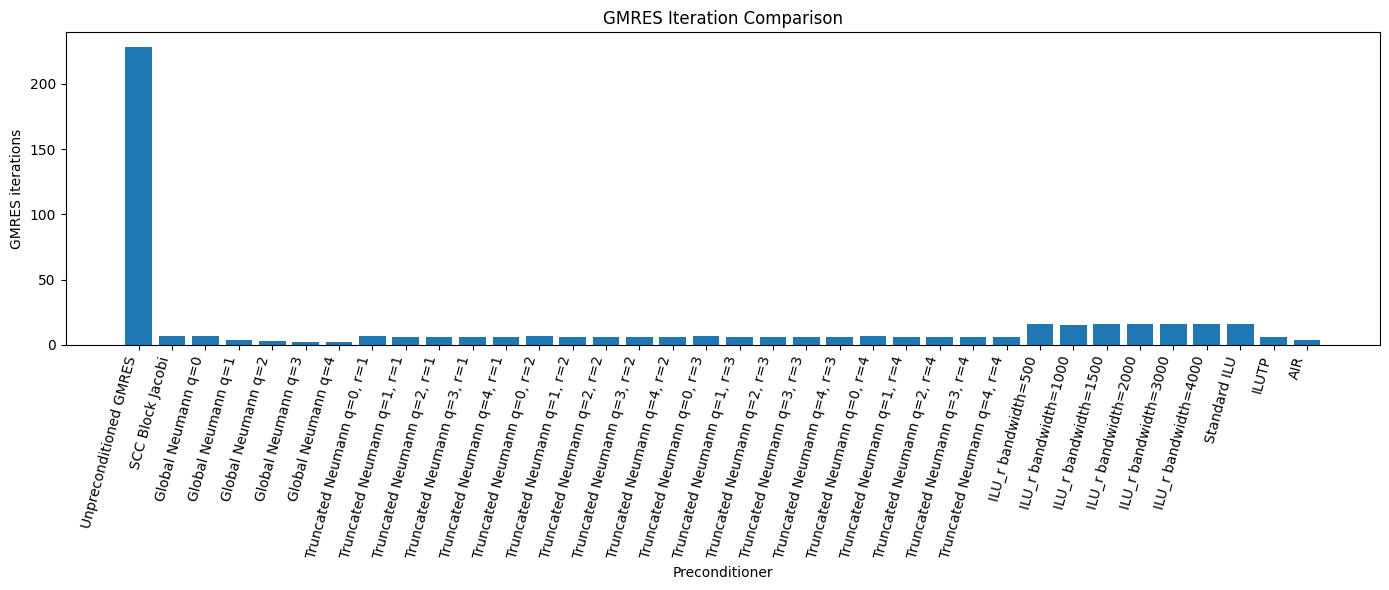

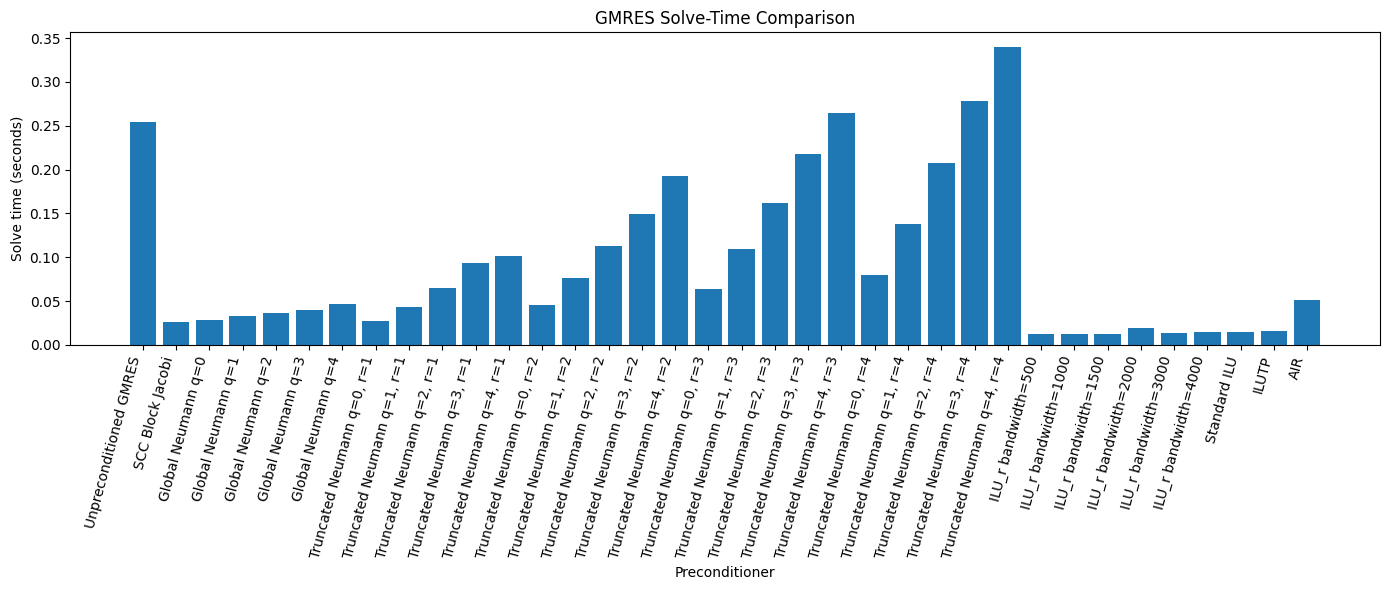

In [4]:
# ================================================================
# SCC PRECONDITIONERS + SCALAR-BAND ILU_r
# Dataset: SNAP Wiki-Vote
#
# Methods:
#   1. GMRES without preconditioning
#   2. SCC Block Jacobi
#   3. Global SCC Neumann preconditioner M_q
#   4. Band-truncated SCC Neumann preconditioner M_(q,r)
#   5. ILU_r: ILU of SCC-aware scalar-band truncation A_r
#   6. ILU
#   7. ILUTP
#   8. AIR (optional, requires PyAMG)
#
# All iterative methods solve the ORIGINAL system A x = b.
# All preconditioners are applied as RIGHT preconditioners.
# ================================================================


# ================================================================
# 0. INSTALL AND IMPORT
# ================================================================

!pip -q install scipy numpy pandas networkx pyamg

import os
import time
import gzip
import urllib.request
import warnings

import numpy as np
import pandas as pd
import scipy.sparse as sp
import scipy.sparse.linalg as spla

import networkx as nx

from scipy.sparse.csgraph import connected_components
from scipy.sparse.linalg import LinearOperator, gmres, spilu

warnings.filterwarnings("ignore")

np.random.seed(42)


# ================================================================
# 1. EXPERIMENT PARAMETERS
# ================================================================

DATA_URL = "https://snap.stanford.edu/data/wiki-Vote.txt.gz"
DATA_FILE = "/content/wiki-Vote.txt.gz"

# Global Neumann orders.
Q_VALUES = [0, 1, 2, 3, 4]

# SCC-band parameters for T_r.
# Actual scalar bandwidth = r * maximum SCC size.
R_VALUES = [1, 2, 3, 4]

# Scalar bandwidths for ILU_r.
# These are actual scalar offsets in the SCC ordering.
ILUR_BANDWIDTHS = [500, 1000, 1500, 2000, 3000, 4000]

# GMRES parameters.
GMRES_RTOL = 1e-8
GMRES_ATOL = 0.0
GMRES_RESTART = 50
GMRES_MAXITER = 500

# For constructing T_r in row batches.
T_BAND_ROW_BATCH = 512

# Random right-hand side.
RHS_SEED = 12345

# Set False if you do not want to run AIR.
RUN_AIR = True

# Output files.
RESULTS_FILE = "/content/wiki_vote_scc_results.csv"


# ================================================================
# 2. DOWNLOAD WIKI-VOTE DATASET
# ================================================================

if not os.path.exists(DATA_FILE):
    print("Downloading Wiki-Vote dataset...")
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)

print("Dataset downloaded:", DATA_FILE)


# ================================================================
# 3. LOAD DIRECTED GRAPH
# ================================================================

def load_snap_graph(filename):
    """
    Load a SNAP edge-list graph.

    Original vertex IDs are mapped to consecutive indices.
    This is important because SNAP vertex IDs are not necessarily
    consecutive integers from 0 to n-1.
    """

    print("Loading graph...")

    edges = []

    with gzip.open(filename, "rt") as f:
        for line in f:

            line = line.strip()

            if not line or line.startswith("#"):
                continue

            parts = line.split()

            if len(parts) < 2:
                continue

            u = int(parts[0])
            v = int(parts[1])

            if u != v:
                edges.append((u, v))

    edges = np.asarray(edges, dtype=np.int64)

    rows_original = edges[:, 0]
    cols_original = edges[:, 1]

    # Map arbitrary original IDs to 0,1,...,n-1.
    original_vertex_ids = np.unique(
        np.concatenate([rows_original, cols_original])
    )

    rows = np.searchsorted(original_vertex_ids, rows_original)
    cols = np.searchsorted(original_vertex_ids, cols_original)

    n = len(original_vertex_ids)

    W = sp.csr_matrix(
        (
            np.ones(len(rows), dtype=np.float64),
            (rows, cols)
        ),
        shape=(n, n)
    )

    # Remove duplicate edges.
    W.sum_duplicates()

    # Convert all nonzero entries to 1.
    W.data[:] = 1.0

    W.eliminate_zeros()

    print("\nGraph statistics")
    print("----------------")
    print("Number of vertices:", W.shape[0])
    print("Number of directed edges:", W.nnz)

    return W, original_vertex_ids


W_original, original_vertex_ids = load_snap_graph(DATA_FILE)

n = W_original.shape[0]


# ================================================================
# 4. BUILD ORIGINAL SHIFTED DIRECTED LAPLACIAN
# ================================================================

def build_shifted_laplacian(W):
    """
    A = I + diag(outdegree) - W

    W(i,j) > 0 means edge i -> j.
    """

    n = W.shape[0]

    outdegree = np.asarray(W.sum(axis=1)).ravel()

    A = (
        sp.eye(n, format="csr")
        + sp.diags(outdegree, format="csr")
        - W
    )

    A.eliminate_zeros()

    return A


A_original = build_shifted_laplacian(W_original)

print("\nOriginal matrix:")
print("Shape:", A_original.shape)
print("Nonzeros:", A_original.nnz)


# ================================================================
# 5. COMPUTE SCC DECOMPOSITION AND TOPOLOGICAL ORDERING
# ================================================================

print("\nComputing strongly connected components...")

number_of_scc, labels = connected_components(
    W_original,
    directed=True,
    connection="strong",
    return_labels=True
)

print("Number of SCCs:", number_of_scc)

scc_sizes = np.bincount(labels, minlength=number_of_scc)

print("Largest SCC size:", scc_sizes.max())
print("Smallest SCC size:", scc_sizes.min())


# ------------------------------------------------
# Construct condensation graph.
# ------------------------------------------------

print("Constructing condensation DAG...")

W_coo = W_original.tocoo()

different_scc = labels[W_coo.row] != labels[W_coo.col]

source_components = labels[W_coo.row[different_scc]]
target_components = labels[W_coo.col[different_scc]]

component_edges = np.unique(
    np.column_stack(
        [source_components, target_components]
    ),
    axis=0
)

G_condensation = nx.DiGraph()

G_condensation.add_nodes_from(range(number_of_scc))

G_condensation.add_edges_from(component_edges.tolist())

if not nx.is_directed_acyclic_graph(G_condensation):
    raise RuntimeError("The SCC condensation graph is not a DAG.")

topological_scc_order = list(
    nx.topological_sort(G_condensation)
)

print("Topological SCC ordering completed.")


# ------------------------------------------------
# Permute vertices according to topological SCC order.
# ------------------------------------------------

permutation_parts = []

for component in topological_scc_order:

    vertices = np.where(labels == component)[0]

    permutation_parts.append(vertices)

perm = np.concatenate(permutation_parts)

inverse_perm = np.empty(n, dtype=np.int64)
inverse_perm[perm] = np.arange(n)

# Labels in the new ordering.
labels_ordered = labels[perm]

# Contiguous SCC blocks in the new ordering.
ordered_scc_sizes = np.array(
    [len(part) for part in permutation_parts],
    dtype=np.int64
)

scc_starts = np.concatenate(
    ([0], np.cumsum(ordered_scc_sizes))
)

scc_blocks = []

for k in range(number_of_scc):

    start = scc_starts[k]
    end = scc_starts[k + 1]

    scc_blocks.append(
        np.arange(start, end, dtype=np.int64)
    )

max_scc_size = int(ordered_scc_sizes.max())

print("\nSCC ordering statistics")
print("-----------------------")
print("Number of SCCs:", number_of_scc)
print("Maximum SCC size:", max_scc_size)
print("Minimum SCC size:", ordered_scc_sizes.min())


# ================================================================
# 6. PERMUTE A AND W
# ================================================================

print("\nPermuting matrices...")

A = A_original[perm, :][:, perm].tocsr()
W = W_original[perm, :][:, perm].tocsr()

A.eliminate_zeros()
W.eliminate_zeros()


# ================================================================
# 7. CONSTRUCT D AND E
#
# A = D - E
#
# D contains:
#   - all entries inside diagonal SCC blocks
#   - the original diagonal entries
#
# E contains:
#   - all inter-SCC adjacency entries
#
# Therefore D preserves the original full outdegree diagonal.
# ================================================================

print("\nConstructing D and E...")

W_coo = W.tocoo()

same_scc = (
    labels_ordered[W_coo.row]
    == labels_ordered[W_coo.col]
)

inter_scc = ~same_scc

E = sp.csr_matrix(
    (
        W_coo.data[inter_scc],
        (
            W_coo.row[inter_scc],
            W_coo.col[inter_scc]
        )
    ),
    shape=(n, n)
)

E.eliminate_zeros()

# D = A + E.
D = (A + E).tocsr()

D.eliminate_zeros()

print("D nonzeros:", D.nnz)
print("E nonzeros:", E.nnz)

# Check A = D - E.
difference = A - (D - E)

if difference.nnz > 0:
    if np.max(np.abs(difference.data)) > 1e-12:
        raise RuntimeError("A != D - E.")

print("Verified: A = D - E.")


# ================================================================
# 8. FACTORIZE SCC DIAGONAL BLOCKS
# ================================================================

print("\nFactorizing SCC diagonal blocks...")

D_factors = []
D_single_vertices = []
D_single_values = []

factorization_start = time.perf_counter()

for k, vertices in enumerate(scc_blocks):

    D_block = D[vertices, :][:, vertices].tocsc()

    if len(vertices) == 1:

        # Optimize singleton SCCs.
        value = D_block[0, 0]

        if abs(value) < 1e-14:
            raise RuntimeError("Zero singleton diagonal block.")

        D_factors.append(None)

        D_single_vertices.append(vertices[0])
        D_single_values.append(value)

    else:

        factor = spla.splu(D_block)

        D_factors.append(factor)

D_factorization_time = time.perf_counter() - factorization_start

D_single_vertices = np.asarray(
    D_single_vertices,
    dtype=np.int64
)

D_single_values = np.asarray(
    D_single_values,
    dtype=np.float64
)

print("SCC factorization time:", D_factorization_time)
print("Singleton SCCs:", len(D_single_vertices))
print("Non-singleton SCCs:", number_of_scc - len(D_single_vertices))


# ================================================================
# 9. MATRIX-FREE SOLVE WITH D
# ================================================================

def Dsolve(v):
    """
    Compute D^{-1} v using cached SCC LU factorizations.

    No explicit inverse of D is formed.
    """

    v = np.asarray(v).reshape(-1)

    result = np.zeros_like(v, dtype=np.float64)

    # Vectorized singleton solves.
    result[D_single_vertices] = (
        v[D_single_vertices] / D_single_values
    )

    # Non-singleton SCC solves.
    for k, vertices in enumerate(scc_blocks):

        factor = D_factors[k]

        if factor is None:
            continue

        result[vertices] = factor.solve(v[vertices])

    return result


def Dsolve_transpose(v):
    """
    Compute D^{-T} v using cached LU factors.
    """

    v = np.asarray(v).reshape(-1)

    result = np.zeros_like(v, dtype=np.float64)

    result[D_single_vertices] = (
        v[D_single_vertices] / D_single_values
    )

    for k, vertices in enumerate(scc_blocks):

        factor = D_factors[k]

        if factor is None:
            continue

        result[vertices] = factor.solve(
            v[vertices],
            trans="T"
        )

    return result


# Verify Dsolve.
test_vector = np.random.randn(n)

test_solution = Dsolve(test_vector)

solve_error = np.linalg.norm(
    D @ test_solution - test_vector
) / np.linalg.norm(test_vector)

print("\nD solve relative error:", solve_error)


# ================================================================
# 10. COMMON RIGHT-PRECONDITIONED GMRES ROUTINE
# ================================================================

results = []


def run_right_preconditioned_gmres(
    method_name,
    M,
    setup_time,
    extra_info=None
):
    """
    Solve A M y = b, then recover x = M y.

    This is RIGHT preconditioning.

    The original system A x = b is used for final residuals.
    """

    rng = np.random.default_rng(RHS_SEED)

    b = rng.standard_normal(n)

    # Right-preconditioned operator.
    AM = LinearOperator(
        shape=(n, n),
        matvec=lambda y: A @ M.matvec(y),
        dtype=np.float64
    )

    iteration_count = [0]

    def callback(residual_norm):
        iteration_count[0] += 1

    # Measure one preconditioner application.
    test_v = np.random.randn(n)

    apply_start = time.perf_counter()
    test_result = M.matvec(test_v)
    apply_time = time.perf_counter() - apply_start

    # GMRES solve.
    solve_start = time.perf_counter()

    y, info = gmres(
        AM,
        b,
        rtol=GMRES_RTOL,
        atol=GMRES_ATOL,
        restart=GMRES_RESTART,
        maxiter=GMRES_MAXITER,
        callback=callback,
        callback_type="pr_norm"
    )

    solve_time = time.perf_counter() - solve_start

    # Recover original solution.
    x = M.matvec(y)

    # True residual against ORIGINAL A.
    true_residual = np.linalg.norm(A @ x - b) / np.linalg.norm(b)

    record = {
        "Method": method_name,
        "Setup_Time": setup_time,
        "Apply_Time": apply_time,
        "Solve_Time": solve_time,
        "Iterations": iteration_count[0],
        "GMRES_Info": info,
        "Relative_Residual": true_residual
    }

    if extra_info is not None:
        record.update(extra_info)

    results.append(record)

    print("\n", method_name)
    print("-" * 60)
    print("Setup time:", setup_time)
    print("Apply time:", apply_time)
    print("Solve time:", solve_time)
    print("Iterations:", iteration_count[0])
    print("GMRES info:", info)
    print("True relative residual:", true_residual)

    return x


# ================================================================
# 11. UNPRECONDITIONED GMRES
# ================================================================

print("\nRunning unpreconditioned GMRES...")

identity_operator = LinearOperator(
    (n, n),
    matvec=lambda v: v,
    dtype=np.float64
)

run_right_preconditioned_gmres(
    "Unpreconditioned GMRES",
    identity_operator,
    setup_time=0.0
)


# ================================================================
# 12. SCC BLOCK JACOBI PRECONDITIONER
#
# M = D^{-1}
# ================================================================

print("\nRunning SCC Block Jacobi...")

block_jacobi_operator = LinearOperator(
    (n, n),
    matvec=Dsolve,
    dtype=np.float64
)

run_right_preconditioned_gmres(
    "SCC Block Jacobi",
    block_jacobi_operator,
    setup_time=D_factorization_time
)


# ================================================================
# 13. GLOBAL SCC NEUMANN PRECONDITIONER
#
# M_q = D^{-1} sum_{j=0}^q (E D^{-1})^j
#
# Matrix-free application:
#
# z = v
# out = 0
# for j = 0,...,q:
#     u = D^{-1} z
#     out += u
#     z = E u
# ================================================================

def make_global_neumann_operator(q):

    def apply(v):

        z = np.asarray(v).copy()

        out = np.zeros_like(z, dtype=np.float64)

        for _ in range(q + 1):

            u = Dsolve(z)

            out += u

            z = E @ u

        return out

    return LinearOperator(
        (n, n),
        matvec=apply,
        dtype=np.float64
    )


print("\nRunning global SCC Neumann methods...")

for q in Q_VALUES:

    Mq = make_global_neumann_operator(q)

    run_right_preconditioned_gmres(
        f"Global Neumann q={q}",
        Mq,
        setup_time=D_factorization_time,
        extra_info={"q": q}
    )


# ================================================================
# 14. BUILD BAND-TRUNCATED T_r
#
# T = E D^{-1}
#
# T_r retains entries satisfying:
#
#     0 <= col - row <= scalar_bandwidth
#
# The scalar bandwidth is:
#
#     scalar_bandwidth = r * maximum_SCC_size
#
# IMPORTANT:
# T_r is constructed from E[:,S_j] D_j^{-1}.
# We do not truncate E before multiplying by D^{-1}.
# ================================================================

def build_T_band(r, scalar_bandwidth=None):

    if scalar_bandwidth is None:
        scalar_bandwidth = r * max_scc_size

    print(
        f"\nBuilding T_r: r={r}, "
        f"scalar bandwidth={scalar_bandwidth}"
    )

    start_time = time.perf_counter()

    T_rows = []
    T_cols = []
    T_data = []

    row_batches = [
        np.arange(i, min(i + T_BAND_ROW_BATCH, n))
        for i in range(0, n, T_BAND_ROW_BATCH)
    ]

    E_csr = E.tocsr()

    for k, vertices in enumerate(scc_blocks):

        factor = D_factors[k]

        # E[:, S_j]
        E_block_column = E_csr[:, vertices].tocsr()

        if E_block_column.nnz == 0:
            continue

        for row_indices in row_batches:

            B = E_block_column[row_indices, :].toarray()

            if not np.any(B):
                continue

            if factor is None:

                # Singleton SCC.
                X = B / D_single_values[
                    np.searchsorted(
                        D_single_vertices,
                        vertices[0]
                    )
                ]

            else:

                # Compute B D_j^{-1} through transpose solves:
                #
                # (B D_j^{-1})^T = D_j^{-T} B^T
                X = factor.solve(
                    B.T,
                    trans="T"
                ).T

            # Scalar-band mask.
            global_rows = row_indices[:, None]
            global_cols = vertices[None, :]

            delta = global_cols - global_rows

            keep = (
                (delta >= 0)
                & (delta <= scalar_bandwidth)
            )

            keep &= (X != 0)

            local_i, local_j = np.nonzero(keep)

            if len(local_i) == 0:
                continue

            T_rows.append(row_indices[local_i])
            T_cols.append(vertices[local_j])
            T_data.append(X[local_i, local_j])

    if len(T_data) == 0:

        T_r = sp.csr_matrix((n, n), dtype=np.float64)

    else:

        T_r = sp.csr_matrix(
            (
                np.concatenate(T_data),
                (
                    np.concatenate(T_rows),
                    np.concatenate(T_cols)
                )
            ),
            shape=(n, n)
        )

    T_r.sum_duplicates()
    T_r.eliminate_zeros()

    construction_time = time.perf_counter() - start_time

    print("T_r nonzeros:", T_r.nnz)
    print("T_r construction time:", construction_time)

    return T_r, construction_time


# ================================================================
# 15. BAND-TRUNCATED (q,r) NEUMANN PRECONDITIONER
#
# M_(q,r) = D^{-1} sum_{k=0}^q T_r^k
#
# ================================================================

def make_truncated_neumann_operator(q, T_r):

    def apply(v):

        z = np.asarray(v).copy()

        out = np.zeros_like(z, dtype=np.float64)

        for _ in range(q + 1):

            u = Dsolve(z)

            out += u

            z = T_r @ u

        return out

    return LinearOperator(
        (n, n),
        matvec=apply,
        dtype=np.float64
    )


print("\nRunning band-truncated (q,r) methods...")

for r in R_VALUES:

    T_r, T_r_setup_time = build_T_band(r)

    for q in Q_VALUES:

        Mqr = make_truncated_neumann_operator(q, T_r)

        run_right_preconditioned_gmres(
            f"Truncated Neumann q={q}, r={r}",
            Mqr,
            setup_time=(
                D_factorization_time + T_r_setup_time
            ),
            extra_info={
                "q": q,
                "r": r,
                "T_r_nnz": T_r.nnz
            }
        )


# ================================================================
# 16. CORRECT SCC-AWARE SCALAR-BAND TRUNCATION OF A
#
# This is the corrected function.
#
# Preserve:
#   - ALL entries inside each diagonal SCC block.
#
# Keep inter-SCC entries only when:
#   0 <= col - row <= bandwidth
#
# The diagonal SCC blocks are NOT assumed to be scalar
# upper triangular.
# ================================================================

def scalar_upper_band_truncation(
    A_perm,
    bandwidth,
    labels_ordered
):
    """
    Construct SCC-aware scalar-band matrix A_r.

    All entries within each diagonal SCC block are preserved.

    Inter-SCC entries are retained only if:

        0 <= col - row <= bandwidth

    This is compatible with block upper-triangular SCC ordering.
    """

    start = time.perf_counter()

    A_coo = A_perm.tocoo()

    row = A_coo.row
    col = A_coo.col

    # Entries inside the same SCC.
    same_scc = (
        labels_ordered[row] == labels_ordered[col]
    )

    # Scalar upper-band condition.
    delta = col - row

    within_band = (
        (delta >= 0)
        & (delta <= bandwidth)
    )

    # Preserve complete diagonal SCC blocks.
    # Truncate only inter-SCC entries outside the band.
    keep = same_scc | ((~same_scc) & within_band)

    A_band = sp.csr_matrix(
        (
            A_coo.data[keep],
            (
                row[keep],
                col[keep]
            )
        ),
        shape=A_perm.shape
    )

    A_band.sum_duplicates()
    A_band.eliminate_zeros()

    truncation_time = time.perf_counter() - start

    return A_band, truncation_time


# ================================================================
# 17. NEW METHOD: SCALAR-BAND ILU_r
#
# For each bandwidth:
#
#   1. Construct SCC-aware A_r.
#   2. Compute ILU(A_r).
#   3. Use ILU(A_r) as a RIGHT preconditioner.
#   4. Solve the ORIGINAL system A x = b.
#
# IMPORTANT:
# GMRES is NOT solving A_r x = b.
# ================================================================

print("\n")
print("=" * 70)
print("NEW METHOD: SCC-AWARE SCALAR-BAND ILU_r")
print("=" * 70)


for bandwidth in ILUR_BANDWIDTHS:

    print(
        "\nConstructing A_r with scalar bandwidth:",
        bandwidth
    )

    # ------------------------------------------------
    # Construct SCC-aware banded matrix.
    # ------------------------------------------------

    A_band, truncation_time = scalar_upper_band_truncation(
        A,
        bandwidth,
        labels_ordered
    )

    print("A_r nonzeros:", A_band.nnz)
    print("Original A nonzeros:", A.nnz)
    print("A_r construction time:", truncation_time)

    # ------------------------------------------------
    # ILU factorization of A_r.
    # ------------------------------------------------

    print("Computing ILU(A_r)...")

    ilu_start = time.perf_counter()

    ilu_factor = spilu(
        A_band.tocsc(),
        drop_tol=0.0,
        fill_factor=1.0,
        permc_spec="COLAMD"
    )

    ilu_setup_time = time.perf_counter() - ilu_start

    print("ILU factorization time:", ilu_setup_time)

    # ------------------------------------------------
    # Right preconditioner.
    #
    # M(v) = ILU(A_r)^{-1} v
    # ------------------------------------------------

    M_ilu_r = LinearOperator(
        (n, n),
        matvec=ilu_factor.solve,
        dtype=np.float64
    )

    # ------------------------------------------------
    # Solve original A x = b using right preconditioning.
    # ------------------------------------------------

    run_right_preconditioned_gmres(
        f"ILU_r bandwidth={bandwidth}",
        M_ilu_r,
        setup_time=(
            truncation_time + ilu_setup_time
        ),
        extra_info={
            "bandwidth": bandwidth,
            "A_r_nnz": A_band.nnz,
            "ILU_factor_nnz": (
                ilu_factor.L.nnz + ilu_factor.U.nnz
            )
        }
    )

    del ilu_factor
    del M_ilu_r
    del A_band


# ================================================================
# 18. STANDARD ILU
# ================================================================

print("\nRunning standard ILU...")

ilu_start = time.perf_counter()

standard_ilu = spilu(
    A.tocsc(),
    drop_tol=0.0,
    fill_factor=1.0,
    permc_spec="COLAMD"
)

standard_ilu_time = time.perf_counter() - ilu_start

M_standard_ilu = LinearOperator(
    (n, n),
    matvec=standard_ilu.solve,
    dtype=np.float64
)

run_right_preconditioned_gmres(
    "Standard ILU",
    M_standard_ilu,
    setup_time=standard_ilu_time,
    extra_info={
        "ILU_factor_nnz": (
            standard_ilu.L.nnz + standard_ilu.U.nnz
        )
    }
)

del standard_ilu


# ================================================================
# 19. ILUTP
# ================================================================

print("\nRunning ILUTP...")

ilutp_start = time.perf_counter()

ilutp_factor = spilu(
    A.tocsc(),
    drop_tol=1e-4,
    fill_factor=10.0,
    permc_spec="COLAMD"
)

ilutp_time = time.perf_counter() - ilutp_start

M_ilutp = LinearOperator(
    (n, n),
    matvec=ilutp_factor.solve,
    dtype=np.float64
)

run_right_preconditioned_gmres(
    "ILUTP",
    M_ilutp,
    setup_time=ilutp_time,
    extra_info={
        "ILU_factor_nnz": (
            ilutp_factor.L.nnz + ilutp_factor.U.nnz
        )
    }
)

del ilutp_factor


# ================================================================
# 20. AIR PRECONDITIONER (OPTIONAL)
# ================================================================

if RUN_AIR:

    print("\nRunning AIR...")

    try:

        import pyamg

        air_start = time.perf_counter()

        air_solver = pyamg.air_solver(
            A,
            interpolation="one_point"
        )

        air_setup_time = time.perf_counter() - air_start

        M_air = LinearOperator(
            (n, n),
            matvec=lambda v: air_solver.solve(
                v,
                tol=0.0,
                maxiter=1,
                cycle="V"
            ),
            dtype=np.float64
        )

        run_right_preconditioned_gmres(
            "AIR",
            M_air,
            setup_time=air_setup_time
        )

    except Exception as e:

        print("AIR could not be executed:")
        print(e)


# ================================================================
# 21. SAVE RESULTS
# ================================================================

results_df = pd.DataFrame(results)

results_df.to_csv(
    RESULTS_FILE,
    index=False
)

print("\n")
print("=" * 70)
print("EXPERIMENT COMPLETED")
print("=" * 70)

print("\nResults:")
display(results_df)

print("\nResults saved to:")
print(RESULTS_FILE)


# ================================================================
# 22. SORT RESULTS BY ITERATION COUNT
# ================================================================

print("\nMethods sorted by iteration count:")

display(
    results_df.sort_values(
        by="Iterations",
        ascending=True
    )
)


# ================================================================
# 23. OPTIONAL: PLOT ITERATION COUNTS
# ================================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.bar(
    results_df["Method"],
    results_df["Iterations"]
)

plt.xticks(
    rotation=75,
    ha="right"
)

plt.ylabel("GMRES iterations")
plt.xlabel("Preconditioner")
plt.title("GMRES Iteration Comparison")

plt.tight_layout()
plt.show()


# ================================================================
# 24. OPTIONAL: PLOT SOLVE TIMES
# ================================================================

plt.figure(figsize=(14, 6))

plt.bar(
    results_df["Method"],
    results_df["Solve_Time"]
)

plt.xticks(
    rotation=75,
    ha="right"
)

plt.ylabel("Solve time (seconds)")
plt.xlabel("Preconditioner")
plt.title("GMRES Solve-Time Comparison")

plt.tight_layout()
plt.show()